# 09 — Ensemble Models: Bagging and Boosting (Part 2, Phase 4)

Build **random forests (bagging)** and **histogram gradient boosting (boosting)** for interest-rate regression and three-class repayment classification. Reusable object-oriented implementations are in `Python/ensemble_models.py`, extending Notebook 08's fold-aware experiment runner.

Keep the same feature plan, prediction times, chronological split, training CV, metrics, and complete validation cohorts. **No test data are read.** Select each family's hyperparameters using training CV before external validation scoring. The joint-applicant feature issue diagnosed in Notebook 08 is retained and assessed, not silently repaired.

In [1]:
import sys, json, platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from Python.modelling_setup import ModellingDataSetup, ExperimentConfig
from Python.ensemble_models import EnsembleExperimentConfig, EnsembleExperimentRunner

OUT = PROJECT_ROOT / 'outputs' / 'ensembles'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
setup = ModellingDataSetup(PROJECT_ROOT)
protocol = ExperimentConfig()
config = EnsembleExperimentConfig()
runner = EnsembleExperimentRunner(setup, OUT, config, protocol)
metadata = {'configuration': config.to_dict(), 'protocol': protocol.to_dict(),
            'split': setup.split_config, 'predictor_plan': setup.predictor_plan,
            'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'sklearn': sklearn.__version__,
            'sampling': 'All training rows retained; each forest tree uses a bootstrap draw of 50% of fitting rows',
            'selection': 'Training CV mean RMSE minimized / macro F1 maximized per family',
            'test_policy': 'No test rows read; development artifacts only',
            'early_stopping': 'Disabled; fixed boosting iterations, calendar CV only',
            'feature_policy': 'Same allowlists and transforms as Notebook 08; no joint-income repair'}
(OUT / 'experiment_config.json').write_text(json.dumps(metadata, indent=2))
results = {}
started = perf_counter()
display(pd.Series(config.to_dict(), name='setting').to_frame())

,setting
seed,42
blas_threads,2
forest_jobs,2
forest_trees,64
forest_depths,"(12, 20)"
forest_min_samples_leaf,100
forest_max_features,0.5
forest_max_samples,0.5
boosting_iterations,100
boosting_learning_rates,"(0.05, 0.1)"


## 1. Ensemble design and declared computational budget

**Bagging:** a random forest fits trees on independent bootstrap draws and averages their regression predictions or class probabilities. Random feature subsets add diversity. Here each of 64 trees draws 50% of the current fitting rows with replacement; the model receives the entire fitting cohort. Depth (12 or 20) and a minimum leaf size of 100 constrain tree complexity. Each split considers 50% of encoded features. There is no use of out-of-bag performance as a substitute for chronological validation.

**Boosting:** histogram gradient boosting adds trees sequentially to reduce a differentiable objective, using binned predictors for efficiency. Regression uses squared-error loss; classification uses multiclass log loss. Try 15 or 31 leaves. Regression compares learning rates 0.05 and 0.1; classification uses 0.1 and compares ordinary/balanced weights. Use 100 iterations, minimum leaf size 100, and L2 regularization 1.0. Multiclass boosting fits one tree per class per iteration. No random internal early-stopping validation is used.

| Task | Random forest configurations | Boosting configurations | Five-fold CV fits |
|---|---:|---:|---:|
| Regression | 2 depths | 2 learning rates × 2 leaf counts | 30 |
| Classification | 2 depths × 2 class-weight policies | 2 leaf counts × 2 class-weight policies | 40 |

Four additional fits train the selected families on the full training cohorts. Use two forest workers and restrict BLAS/OpenMP to two threads. The 64-tree forest budget revises Part 1's tentative 500-tree proposal to keep full-cohort five-fold experiments practical; it is declared before this run and is not claimed to be optimal. All preprocessing is fitted independently within each training fold and shared only among candidates in that fold. Numeric scaling is retained for consistency even though trees do not require it. Boosting receives the same imputed/encoded inputs, rather than switching silently to native missing/categorical handling.

Regression retains the full-history monthly folds; classification retains initial training through February 2014 and five two-month fold-validation blocks in March–December 2014. Class weights use only current training labels. Balanced probabilities reflect a weighted fitting objective and are not automatically calibrated to population risks.

In inherited result tables, `converged` means the fit emitted no `ConvergenceWarning`. These are fixed-budget ensembles, so this does **not** establish optimization convergence. `budget_completed`, iteration counts, and fitted-tree counts explicitly check that the requested computation finished. Missing historical-feature warnings and varying encoded widths remain documented.

In [2]:
candidate_table = pd.DataFrame([
    {'task': task, 'model': family, 'parameters': json.dumps(parameters, sort_keys=True)}
    for task in ['regression', 'classification'] for family, parameters in runner.factory.candidates(task)])
candidate_table.to_csv(OUT / 'candidate_plan.csv', index=False)
display(candidate_table)
assert len(candidate_table.query("task == 'regression'")) == 6
assert len(candidate_table.query("task == 'classification'")) == 8

,task,model,parameters
0,regression,random_forest,"{""max_depth"": 12}"
1,regression,random_forest,"{""max_depth"": 20}"
2,regression,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 15}"
3,regression,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31}"
4,regression,hist_gradient_boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 15}"
5,regression,hist_gradient_boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31}"
6,classification,random_forest,"{""class_weight"": null, ""max_depth"": 12}"
7,classification,random_forest,"{""class_weight"": ""balanced"", ""max_depth"": 12}"
8,classification,random_forest,"{""class_weight"": null, ""max_depth"": 20}"
9,classification,random_forest,"{""class_weight"": ""balanced"", ""max_depth"": 20}"


## 2. Regression: chronological tuning and full validation

Choose the lowest mean fold RMSE separately for each family. Fold means are unweighted; report fold variability. Select before validation scoring, with parameter-JSON order resolving exact ties. CV selection itself induces optimism. No evaluation rows are sampled.

In [3]:
results['regression'] = runner.run('regression')
display(results['regression'][1])
display(results['regression'][2].dropna(axis=1, how='all'))

regression fold 1: random_forest {'max_depth': 12}; converged=True


regression fold 1: random_forest {'max_depth': 20}; converged=True


regression fold 1: hist_gradient_boosting {'learning_rate': 0.05, 'max_leaf_nodes': 15}; converged=True


regression fold 1: hist_gradient_boosting {'learning_rate': 0.05, 'max_leaf_nodes': 31}; converged=True


regression fold 1: hist_gradient_boosting {'learning_rate': 0.1, 'max_leaf_nodes': 15}; converged=True


regression fold 1: hist_gradient_boosting {'learning_rate': 0.1, 'max_leaf_nodes': 31}; converged=True


... (24 outputs left out)

regression hist_gradient_boosting: full validation and saved-model checks complete


regression random_forest: full validation and saved-model checks complete


,model,parameters,cv_mean,cv_std,n_folds,converged,mean_fit_seconds,eligible
0,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 15}",2.546250,0.644602,5,True,2.057219,True
1,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31}",2.537319,0.655447,5,True,2.381165,True
2,hist_gradient_boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 15}",2.526866,0.677582,5,True,1.851563,True
3,hist_gradient_boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31}",2.531176,0.678226,5,True,2.184352,True
4,random_forest,"{""max_depth"": 12}",2.655990,0.596363,5,True,2.897912,True
5,random_forest,"{""max_depth"": 20}",2.655868,0.597109,5,True,3.026262,True


,model,parameters,n_train,n_evaluation,n_features,fit_seconds,predict_seconds,train_primary,converged,fit_warnings,n_iterations,mae,rmse,r2,trees_fitted,budget_completed,task,partition,preprocessing_seconds,preprocessing_notes
0,hist_gradient_boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 15}",466345,855502,105,15.616717,5.863541,2.569534,True,,100,2.888858,3.588218,0.403233,100,True,regression,validation,2.544706,
1,random_forest,"{""max_depth"": 20}",466345,855502,105,40.283604,3.008489,2.652154,True,,0,2.950886,3.659535,0.379275,64,True,regression,validation,2.544706,


## 3. Classification: macro F1 and minority-class support

Choose the highest mean fold macro F1 for each family, retaining all three labels in every metric. Compare ordinary and balanced weights within training CV. Do not adjust decision thresholds or configurations using external validation. Inspect minority recall and precision separately from accuracy.

In [4]:
results['classification'] = runner.run('classification')
display(results['classification'][1])
display(results['classification'][2].dropna(axis=1, how='all'))
elapsed = perf_counter() - started
(OUT / 'execution_summary.json').write_text(json.dumps({'total_experiment_seconds': elapsed}, indent=2))
print(f'Total experiment runtime: {elapsed / 60:.2f} minutes')

classification fold 1: random_forest {'max_depth': 12, 'class_weight': None}; converged=True


classification fold 1: random_forest {'max_depth': 12, 'class_weight': 'balanced'}; converged=True


classification fold 1: random_forest {'max_depth': 20, 'class_weight': None}; converged=True


classification fold 1: random_forest {'max_depth': 20, 'class_weight': 'balanced'}; converged=True


classification fold 1: hist_gradient_boosting {'learning_rate': 0.1, 'max_leaf_nodes': 15, 'class_weight': None}; converged=True


classification fold 1: hist_gradient_boosting {'learning_rate': 0.1, 'max_leaf_nodes': 15, 'class_weight': 'balanced'}; converged=True


... (35 outputs left out)

classification random_forest: full validation and saved-model checks complete


,model,parameters,cv_mean,cv_std,n_folds,converged,mean_fit_seconds,eligible
0,hist_gradient_boosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",0.386644,0.004294,5,True,28.897369,True
1,hist_gradient_boosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",0.396732,0.008921,5,True,31.677183,True
2,hist_gradient_boosting,"{""class_weight"": null, ""learning_rate"": 0.1, ""...",0.308753,0.004731,5,True,29.564331,True
3,hist_gradient_boosting,"{""class_weight"": null, ""learning_rate"": 0.1, ""...",0.311944,0.006682,5,True,32.572657,True
4,random_forest,"{""class_weight"": ""balanced"", ""max_depth"": 12}",0.372899,0.003762,5,True,22.697317,True
5,random_forest,"{""class_weight"": ""balanced"", ""max_depth"": 20}",0.383396,0.002525,5,True,23.485255,True
6,random_forest,"{""class_weight"": null, ""max_depth"": 12}",0.300226,0.002081,5,True,34.194304,True
7,random_forest,"{""class_weight"": null, ""max_depth"": 20}",0.300758,0.002725,5,True,37.842809,True


,model,parameters,n_train,n_evaluation,n_features,fit_seconds,predict_seconds,train_primary,converged,fit_warnings,...,recall_class_1,n_train_class_1,recall_class_2,n_train_class_2,trees_fitted,budget_completed,task,partition,preprocessing_seconds,preprocessing_notes
0,hist_gradient_boosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",451671,678142,113,42.902007,21.731618,0.416656,True,,...,0.099252,611,0.550230,76500,300,True,classification,validation,2.817876,
1,random_forest,"{""class_weight"": ""balanced"", ""max_depth"": 20}",451671,678142,113,35.069794,3.812348,0.386729,True,,...,0.235486,611,0.462195,76500,64,True,classification,validation,2.817876,


Total experiment runtime: 26.47 minutes


## 4. CV summaries, budget checks, and identical-cohort comparisons

Verify each selected configuration has five valid folds and completed its computation budget. Compare with Notebooks 06–08 on the same validation targets in the same order. kNN used 10,000 training examples, whereas the subsequent models receive all training rows; comparisons with kNN therefore combine model and training-budget effects. Model ranks below describe development validation only.

In [5]:
metric_names = ['mae', 'rmse', 'r2', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
                'precision_micro', 'recall_micro', 'f1_micro', 'auc_macro_ovr', 'auc_micro_ovr',
                'recall_class_0', 'recall_class_1', 'recall_class_2']
summary_rows, selected_folds, comparisons = [], [], {}
for task, (cv, tuning, scores) in results.items():
    selection = json.loads((OUT / f'{task}_selection.json').read_text())['models']
    for family, parameters in selection.items():
        key = json.dumps(parameters, sort_keys=True)
        chosen = cv[(cv.model == family) & (cv.parameters == key)]
        assert len(chosen) == protocol.n_splits and chosen.converged.all()
        selected_folds.append(chosen)
        for metric in metric_names:
            if metric in chosen:
                summary_rows.append(dict(task=task, model=family, metric=metric,
                                         cv_mean=chosen[metric].mean(), cv_std=chosen[metric].std(ddof=1),
                                         n_valid_folds=int(chosen[metric].notna().sum())))
    previous = pd.read_csv(PROJECT_ROOT / f'outputs/supervised/{task}_comparison.csv')
    comparisons[task] = pd.concat([previous, scores], ignore_index=True).dropna(axis=1, how='all')
    assert comparisons[task].n_evaluation.nunique() == 1
    comparisons[task].to_csv(OUT / f'{task}_comparison.csv', index=False)
    prior_predictions = pd.read_parquet(PROJECT_ROOT / f'outputs/supervised/{task}_decision_tree_validation_predictions.parquet')
    target = 'int_rate' if task == 'regression' else 'target_class'
    for family in selection:
        current = pd.read_parquet(OUT / f'{task}_{family}_validation_predictions.parquet')
        np.testing.assert_array_equal(current[target], prior_predictions[target])
        np.testing.assert_array_equal(current.issue_d, prior_predictions.issue_d)
    display(Markdown(f'### {task.title()}: validation comparison'))
    metrics = ['mae', 'rmse', 'r2'] if task == 'regression' else ['accuracy', 'f1_macro', 'recall_macro', 'auc_macro_ovr']
    display(comparisons[task][['model', 'n_train', 'n_evaluation'] + metrics])
cv_summary = pd.DataFrame(summary_rows)
cv_summary.to_csv(OUT / 'selected_cv_summary.csv', index=False)
selected_folds = pd.concat(selected_folds, ignore_index=True)
selected_folds.to_csv(OUT / 'selected_cv_folds.csv', index=False)
display(cv_summary)
display(selected_folds[['task', 'model', 'partition', 'n_train', 'n_features',
                        'train_primary', 'fit_seconds', 'n_iterations', 'trees_fitted', 'budget_completed', 'fit_warnings']])
assert all(frame.converged.all() for _, _, frame in results.values())
assert all(cv.budget_completed.all() and val.budget_completed.all() for cv, _, val in results.values())

### Regression: validation comparison

,model,n_train,n_evaluation,mae,rmse,r2
0,knn_scratch,10000,855502,2.978551,3.768190,0.341868
1,dummy_sample_mean,10000,855502,3.822251,4.740755,-0.041699
2,dummy_sample_median,10000,855502,3.788620,4.717786,-0.031630
3,dummy_mean,466345,855502,3.837982,4.752284,-0.046772
4,dummy_median,466345,855502,3.791029,4.719547,-0.032400
5,decision_tree,466345,855502,2.996727,3.734422,0.353611
6,ridge,466345,855502,3.163244,80.974286,-302.907580
7,hist_gradient_boosting,466345,855502,2.888858,3.588218,0.403233
8,random_forest,466345,855502,2.950886,3.659535,0.379275


### Classification: validation comparison

,model,n_train,n_evaluation,accuracy,f1_macro,recall_macro,auc_macro_ovr
0,knn_scratch,10000,678142,0.763160,0.334668,0.349702,0.565973
1,dummy_sample_prior,10000,678142,0.773577,0.290778,0.333333,0.500000
2,dummy_most_frequent,451671,678142,0.773577,0.290778,0.333333,0.500000
3,dummy_prior,451671,678142,0.773577,0.290778,0.333333,0.500000
4,decision_tree,451671,678142,0.605854,0.389358,0.459884,0.634361
5,logistic,451671,678142,0.591153,0.377292,0.478958,0.657480
6,hist_gradient_boosting,451671,678142,0.666474,0.421880,0.452713,0.696218
7,random_forest,451671,678142,0.638685,0.408874,0.464042,0.675917


,task,model,metric,cv_mean,cv_std,n_valid_folds
0,regression,hist_gradient_boosting,mae,1.977036,0.502999,5
1,regression,hist_gradient_boosting,rmse,2.526866,0.677582,5
2,regression,hist_gradient_boosting,r2,0.512128,0.268109,5
3,regression,random_forest,mae,2.087698,0.464504,5
4,regression,random_forest,rmse,2.655868,0.597109,5
5,regression,random_forest,r2,0.480778,0.229347,5
6,classification,hist_gradient_boosting,accuracy,0.654653,0.005682,5
7,classification,hist_gradient_boosting,precision_macro,0.404933,0.007869,5
8,classification,hist_gradient_boosting,recall_macro,0.451008,0.021679,5
9,classification,hist_gradient_boosting,f1_macro,0.396732,0.008921,5


,task,model,partition,n_train,n_features,train_primary,fit_seconds,n_iterations,trees_fitted,budget_completed,fit_warnings
0,regression,hist_gradient_boosting,cv_1,2412,94,0.580915,0.131344,100,100,True,
1,regression,hist_gradient_boosting,cv_2,8277,95,1.222974,0.296651,100,100,True,
2,regression,hist_gradient_boosting,cv_3,24940,95,1.376903,0.754566,100,100,True,
3,regression,hist_gradient_boosting,cv_4,61058,99,1.238301,1.857188,100,100,True,
4,regression,hist_gradient_boosting,cv_5,186847,104,1.907103,6.218067,100,100,True,
5,regression,random_forest,cv_1,2412,94,1.229795,0.053900,0,64,True,
6,regression,random_forest,cv_2,8277,95,1.555263,0.181864,0,64,True,
7,regression,random_forest,cv_3,24940,95,1.619354,0.749365,0,64,True,
8,regression,random_forest,cv_4,61058,99,1.467386,2.220340,0,64,True,
9,regression,random_forest,cv_5,186847,104,2.143400,11.925842,0,64,True,


## 5. Tuning sensitivity and training-to-fold gaps

Candidate CV means ± fold standard deviations show sensitivity within the declared search. Training scores use each model's complete fitting cohort. Increasing model complexity can reduce fitting error without improving future-vintage prediction. Fold variability is not an independent-sample confidence interval.

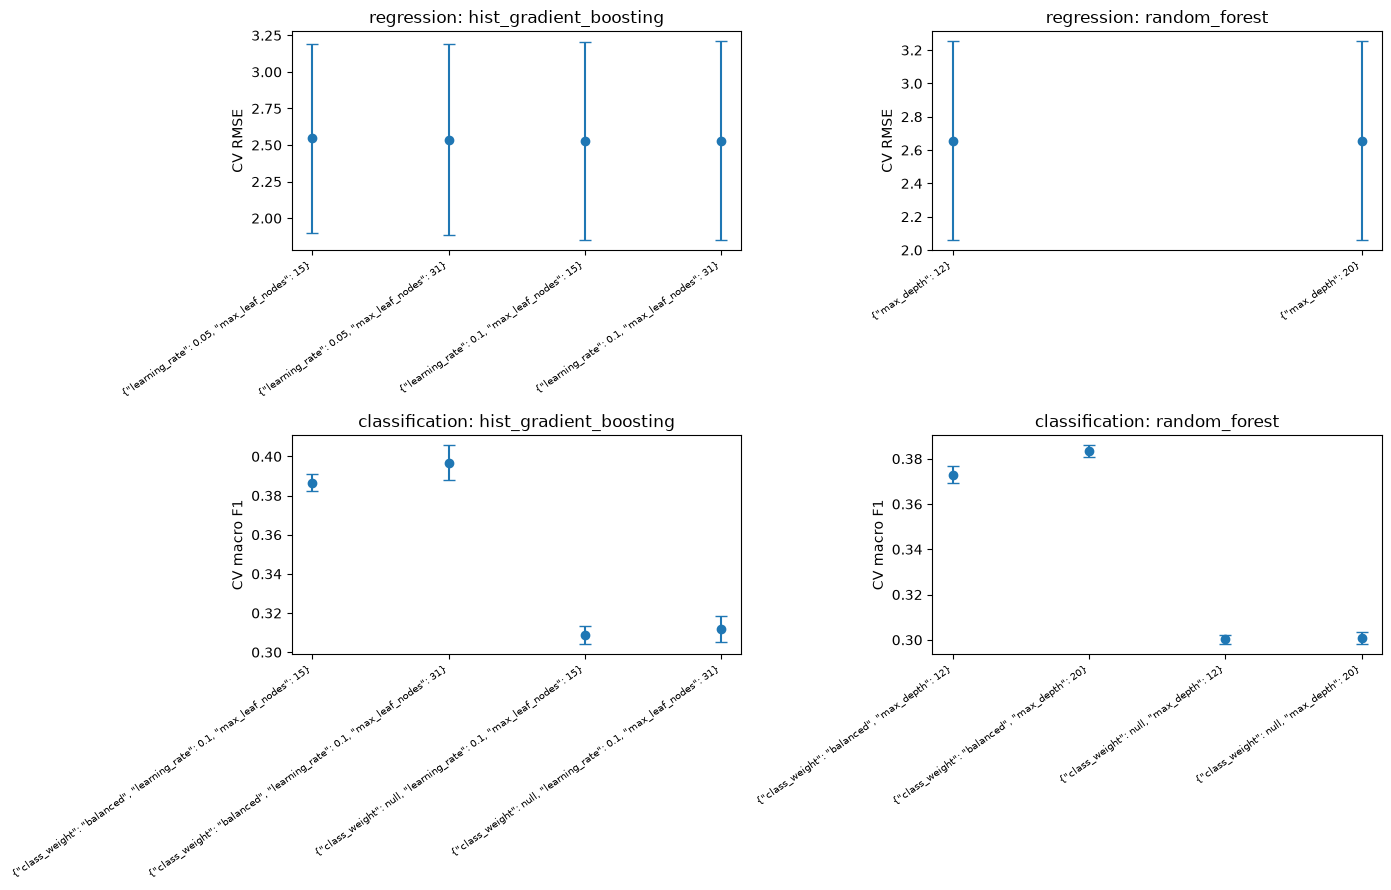

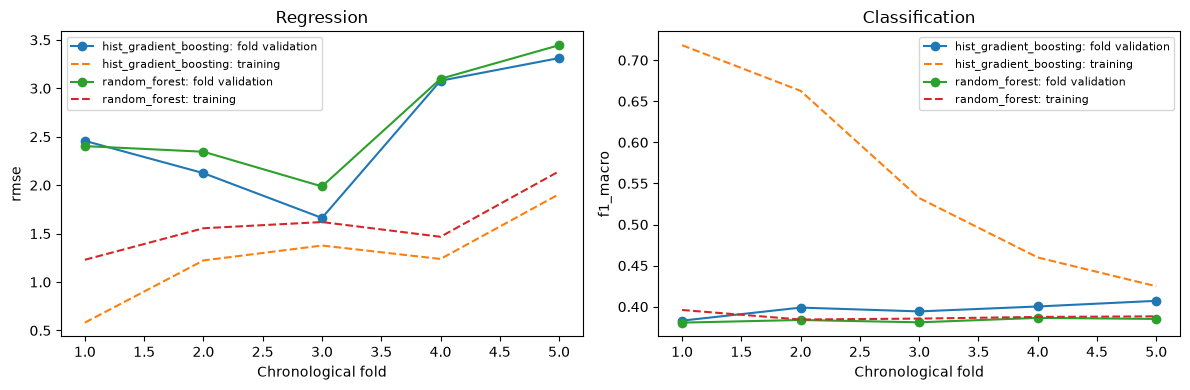

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, task in enumerate(['regression', 'classification']):
    for ax, family in zip(axes[row], sorted(results[task][1].model.unique())):
        frame = results[task][1].query('model == @family').sort_values('parameters')
        ax.errorbar(range(len(frame)), frame.cv_mean, yerr=frame.cv_std, fmt='o', capsize=4)
        ax.set_xticks(range(len(frame)), frame.parameters, rotation=35, ha='right', fontsize=7)
        ax.set(title=f'{task}: {family}', ylabel='CV RMSE' if task == 'regression' else 'CV macro F1')
fig.tight_layout()
fig.savefig(FIG / 'tuning.png', dpi=150)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task in zip(axes, ['regression', 'classification']):
    metric = 'rmse' if task == 'regression' else 'f1_macro'
    for family, frame in selected_folds[selected_folds.task == task].groupby('model'):
        fold = frame.partition.str.extract(r'(\d+)')[0].astype(int)
        ax.plot(fold, frame[metric], marker='o', label=f'{family}: fold validation')
        ax.plot(fold, frame.train_primary, linestyle='--', label=f'{family}: training')
    ax.set(title=task.title(), xlabel='Chronological fold', ylabel=metric)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'training_cv_gaps.png', dpi=150)
plt.show()

## 6. Regression errors and vintage stability

Scatterplots use a seeded display sample only; MAE, RMSE, R² and monthly summaries use every validation row. Positive actual-minus-predicted residuals mean underprediction. Check extreme-rate compression and changes across vintages.

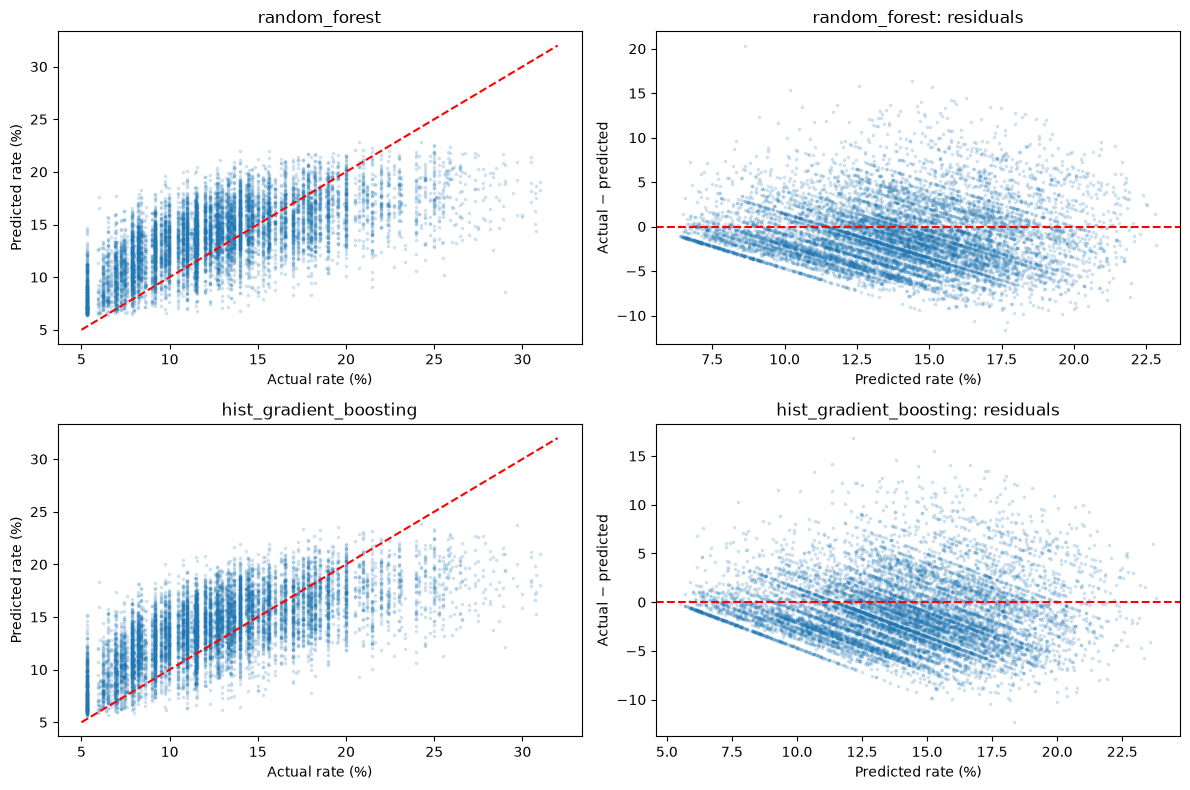

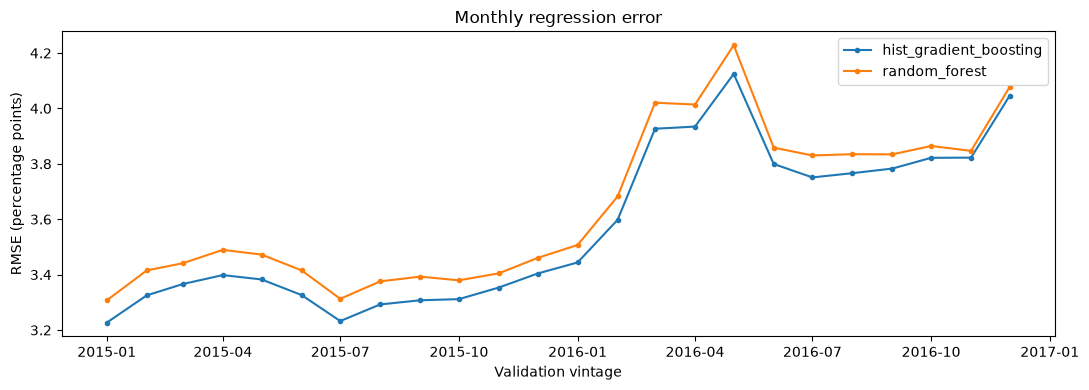

In [7]:
regression_predictions, monthly_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, family in enumerate(['random_forest', 'hist_gradient_boosting']):
    frame = pd.read_parquet(OUT / f'regression_{family}_validation_predictions.parquet')
    frame['residual'] = frame.int_rate - frame.prediction
    regression_predictions[family] = frame
    sample = frame.sample(n=min(10000, len(frame)), random_state=config.seed)
    axes[row, 0].scatter(sample.int_rate, sample.prediction, s=3, alpha=.15)
    axes[row, 0].plot([5, 32], [5, 32], '--', color='red')
    axes[row, 0].set(title=family, xlabel='Actual rate (%)', ylabel='Predicted rate (%)')
    axes[row, 1].scatter(sample.prediction, sample.residual, s=3, alpha=.15)
    axes[row, 1].axhline(0, color='red', linestyle='--')
    axes[row, 1].set(title=f'{family}: residuals', xlabel='Predicted rate (%)', ylabel='Actual − predicted')
    for month, group in frame.groupby(frame.issue_d.dt.to_period('M')):
        monthly_rows.append(dict(model=family, month=str(month), n=len(group),
                                 mae=group.residual.abs().mean(), rmse=np.sqrt(np.mean(group.residual ** 2)),
                                 mean_residual=group.residual.mean()))
fig.tight_layout()
fig.savefig(FIG / 'regression_diagnostics.png', dpi=150)
plt.show()
monthly = pd.DataFrame(monthly_rows)
monthly.to_csv(OUT / 'regression_monthly_errors.csv', index=False)
fig, ax = plt.subplots(figsize=(11, 4))
for family, group in monthly.groupby('model'):
    ax.plot(pd.to_datetime(group.month), group.rmse, marker='.', label=family)
ax.set(xlabel='Validation vintage', ylabel='RMSE (percentage points)', title='Monthly regression error')
ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'regression_monthly_errors.png', dpi=150)
plt.show()

## 7. Classification: false positives, missed outcomes, and ranking

Show raw confusion counts, row-normalized recall, per-class precision/recall/F1, and one-versus-rest ROC curves. Macro AUC describes equal-weight class ranking; micro AUC can be dominated by the frequent Good class. Neither establishes suitable operating decisions or calibrated probabilities.

### random_forest

,precision,recall,f1-score,support
Good,0.861126,0.694444,0.768855,524595.000000
At risk,0.035559,0.235486,0.061788,9491.000000
Default,0.346356,0.462195,0.395977,144056.000000
accuracy,0.638685,0.638685,0.638685,0.638685
macro avg,0.414347,0.464042,0.408874,678142.000000
weighted avg,0.740220,0.638685,0.679750,678142.000000


### hist_gradient_boosting

,precision,recall,f1-score,support
Good,0.862044,0.708657,0.777861,524595.000000
At risk,0.037509,0.099252,0.054443,9491.000000
Default,0.357406,0.550230,0.433336,144056.000000
accuracy,0.666474,0.666474,0.666474,0.666474
macro avg,0.418986,0.452713,0.421880,678142.000000
weighted avg,0.743305,0.666474,0.694550,678142.000000


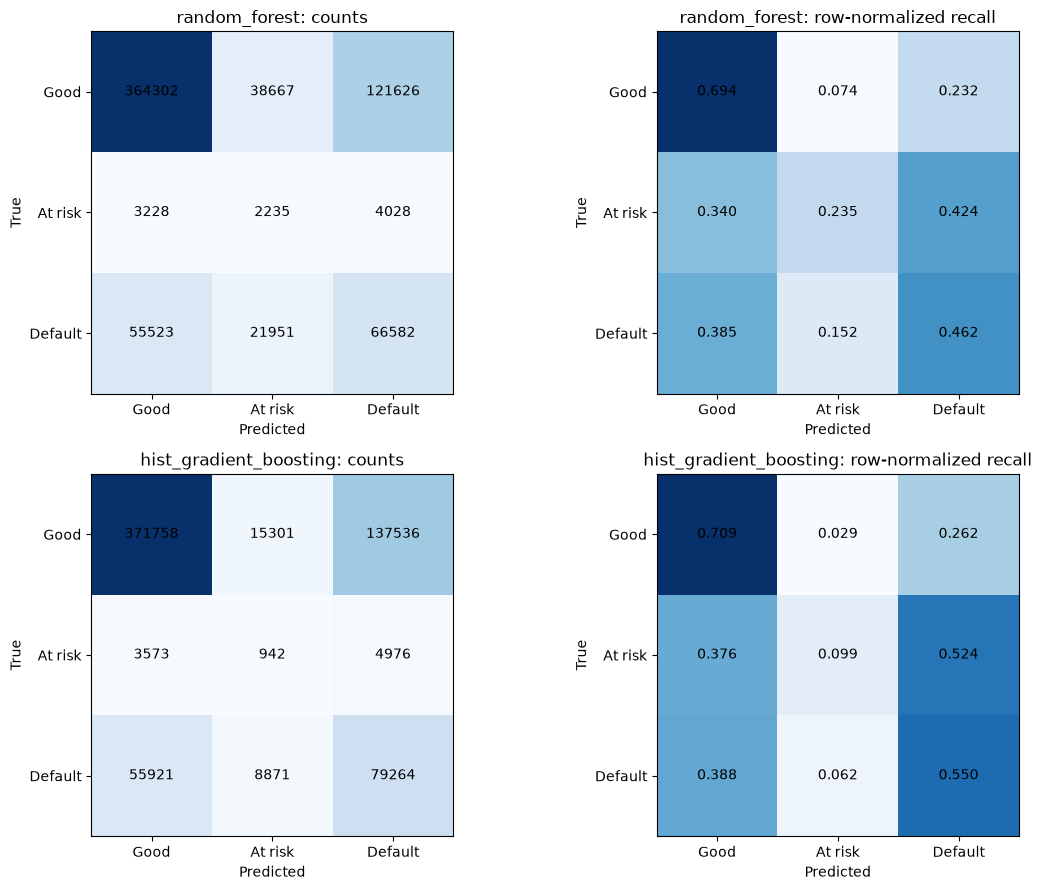

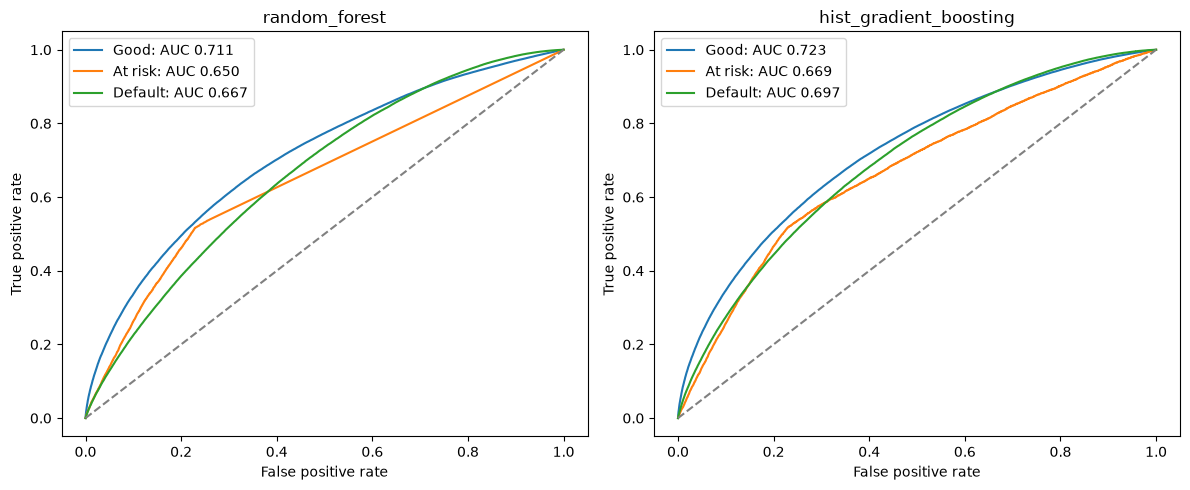

In [8]:
classification_reports, class_auc_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
roc_fig, roc_axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ['Good', 'At risk', 'Default']
for row, family in enumerate(['random_forest', 'hist_gradient_boosting']):
    frame = pd.read_parquet(OUT / f'classification_{family}_validation_predictions.parquet')
    report = pd.DataFrame(classification_report(frame.target_class, frame.prediction, labels=[0, 1, 2],
                                               target_names=labels, zero_division=0, output_dict=True)).T
    classification_reports[family] = report
    report.to_csv(OUT / f'classification_{family}_report.csv')
    display(Markdown(f'### {family}'))
    display(report)
    matrix = confusion_matrix(frame.target_class, frame.prediction, labels=[0, 1, 2])
    pd.DataFrame(matrix, index=labels, columns=labels).to_csv(OUT / f'classification_{family}_confusion.csv')
    for ax, values, name in zip(axes[row], [matrix, matrix / matrix.sum(axis=1, keepdims=True)], ['counts', 'row-normalized recall']):
        ax.imshow(values, cmap='Blues')
        for (i, j), value in np.ndenumerate(values):
            ax.text(j, i, f'{value:.3f}' if values.dtype.kind == 'f' else str(value), ha='center', va='center')
        ax.set(xticks=range(3), yticks=range(3), xticklabels=labels, yticklabels=labels,
               xlabel='Predicted', ylabel='True', title=f'{family}: {name}')
    for label, name in enumerate(labels):
        fpr, tpr, _ = roc_curve(frame.target_class.eq(label), frame[f'probability_{label}'])
        score = auc(fpr, tpr)
        roc_axes[row].plot(fpr, tpr, label=f'{name}: AUC {score:.3f}')
        class_auc_rows.append(dict(model=family, label=name, auc=score))
    roc_axes[row].plot([0, 1], [0, 1], '--', color='gray')
    roc_axes[row].set(title=family, xlabel='False positive rate', ylabel='True positive rate')
    roc_axes[row].legend()
fig.tight_layout()
fig.savefig(FIG / 'classification_confusion_matrices.png', dpi=150)
roc_fig.tight_layout()
roc_fig.savefig(FIG / 'classification_roc.png', dpi=150)
plt.show()
pd.DataFrame(class_auc_rows).to_csv(OUT / 'classification_per_class_auc.csv', index=False)

## 8. Forest interpretation and saved-model structure

Random-forest impurity importances describe how fitted trees allocate split gains. They can favor particular predictors and distribute importance among correlated original/engineered variables; these are not causal effects. Histogram boosting does not expose native impurity importances in this implementation, so fitted structure is reported instead of inventing comparable scores.

Each selected model is saved with fitted preprocessing, input order, task, hyperparameters, split and experiment configuration. Automatic reload checks compare predictions and classification probabilities. These artifacts are fitted on training data only and remain development models.

,property,value
0,iterations,100
1,trees_per_iteration,1
2,encoded_features,105
3,early_stopping,False


,property,value
0,iterations,100
1,trees_per_iteration,3
2,encoded_features,113
3,early_stopping,False


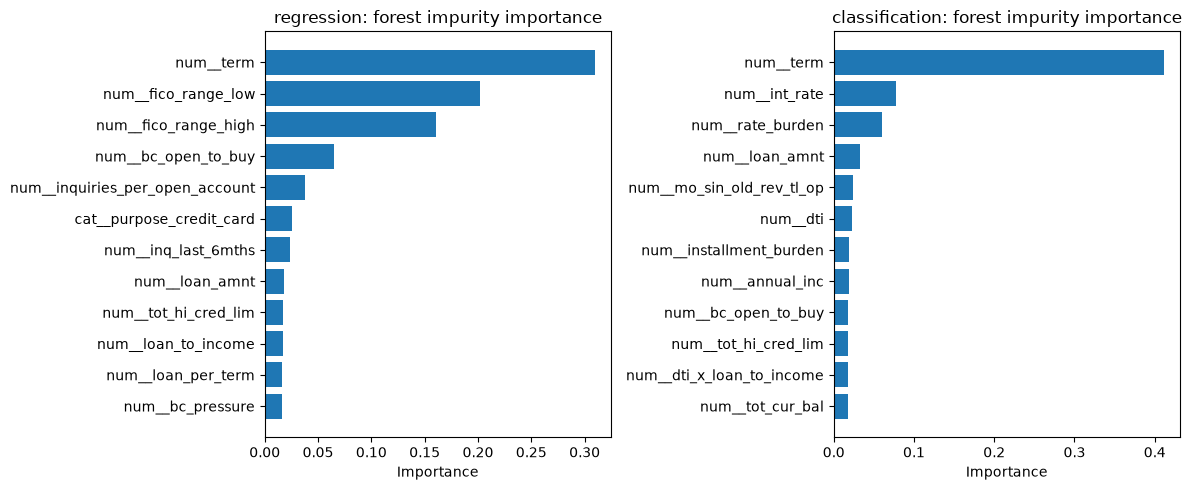

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, task in zip(axes, ['regression', 'classification']):
    effects = pd.read_csv(OUT / f'{task}_random_forest_feature_effects.csv').head(12).iloc[::-1]
    ax.barh(effects.feature, effects.importance)
    ax.set(title=f'{task}: forest impurity importance', xlabel='Importance')
    display(pd.read_csv(OUT / f'{task}_hist_gradient_boosting_structure.csv'))
fig.tight_layout()
fig.savefig(FIG / 'forest_importance.png', dpi=150)
plt.show()

## 9. Joint-application and extreme-ratio diagnostics

Notebook 08 found that joint applications were absent from training but present in validation. A primary-income loan-to-income ratio caused severe Ridge extrapolation on some of those records. Assess ensemble errors by recorded application type without modifying features or fitting another model. These group differences do not isolate a causal effect or establish fairness.

Also inspect the ten largest-error rows selected by the previous Ridge model. That is a validation-derived diagnostic slice, **not** an independent benchmark or tuning target. Retain all rows in overall metrics.

In [10]:
source_path = PROJECT_ROOT / 'data/processed/accepted_regression_fe.parquet'
audit = pd.read_parquet(source_path, columns=['issue_d', 'int_rate', 'application_type'],
    filters=[('issue_d', '>=', pd.Timestamp('2015-01-01')), ('issue_d', '<', pd.Timestamp('2017-01-01'))])
audit = audit.sort_values('issue_d', kind='stable').reset_index(drop=True)
group_rows, extreme_rows = [], []
prior_extremes = pd.read_csv(PROJECT_ROOT / 'outputs/supervised/ridge_extreme_rows.csv')
for family, frame in regression_predictions.items():
    np.testing.assert_array_equal(audit.int_rate, frame.int_rate)
    np.testing.assert_array_equal(audit.issue_d, frame.issue_d)
    for application_type, idx in audit.groupby('application_type', dropna=False).groups.items():
        residual = frame.loc[idx, 'residual']
        group_rows.append(dict(model=family, application_type=application_type, n=len(idx),
                               mae=residual.abs().mean(), rmse=np.sqrt(np.mean(residual ** 2)),
                               mean_residual=residual.mean(), min_prediction=frame.loc[idx, 'prediction'].min(),
                               max_prediction=frame.loc[idx, 'prediction'].max()))
    for _, previous in prior_extremes.iterrows():
        idx = int(previous.partition_row)
        extreme_rows.append(dict(model=family, partition_row=idx, actual_rate=frame.loc[idx, 'int_rate'],
                                 prediction=frame.loc[idx, 'prediction'], ridge_prediction=previous.prediction,
                                 loan_to_income=previous.loan_to_income))
group_errors = pd.DataFrame(group_rows)
extreme_predictions = pd.DataFrame(extreme_rows)
group_errors.to_csv(OUT / 'regression_application_type_errors.csv', index=False)
extreme_predictions.to_csv(OUT / 'regression_extreme_ratio_predictions.csv', index=False)
display(group_errors)
display(extreme_predictions)

,model,application_type,n,mae,rmse,mean_residual,min_prediction,max_prediction
0,random_forest,Individual,846202,2.949591,3.657885,-1.027220,6.358212,23.029102
1,random_forest,Joint App,9300,3.068793,3.806684,-0.988379,6.441917,22.942695
2,hist_gradient_boosting,Individual,846202,2.886416,3.585494,-1.076088,5.436116,25.317142
3,hist_gradient_boosting,Joint App,9300,3.111074,3.828016,-1.285310,5.553660,25.565252


,model,partition_row,actual_rate,prediction,ridge_prediction,loan_to_income
0,random_forest,848183,8.24,15.034635,48334.719939,35000.000000
1,random_forest,590578,7.39,13.042612,33147.444489,24000.000000
2,random_forest,521648,8.39,9.908146,33145.427382,24000.000000
3,random_forest,553781,16.29,16.578090,24867.367808,18000.000000
4,random_forest,755756,11.39,14.626853,20722.228280,15000.000000
5,random_forest,558956,11.47,14.182843,3326.068792,2400.000000
6,random_forest,602655,9.75,11.647661,2163.544881,35.000000
7,random_forest,763334,18.99,15.393043,1274.520262,25.000000
8,random_forest,616015,17.27,16.500440,750.122933,11.666667
9,random_forest,759265,8.24,12.049629,570.494835,14.782609


## 10. Observed results, limits, and handoff

The assessment below reports development results without validation-based retuning. More complex ensembles are not guaranteed to outperform simpler models. Class-weighting gains must be read alongside false-positive costs, and a bounded iteration/tree budget does not establish optimum performance.

Selection of funded loans, exclusion of Current outcomes, unequal follow-up, sparse early At risk labels, changing vintages, application-process changes, potential repeated borrowers, and geography/sensitive proxies remain limitations. Chronological evaluation uses retrospective labels and does not establish a historical backtest. Final test scoring, fairness assessment, and deployment recommendations remain for later notebooks.

In [11]:
lines = ['# Notebook 09 — observed ensemble development results', '']
for task in ['regression', 'classification']:
    cv, tuning, scores = results[task]
    for _, row in scores.iterrows():
        family = row.model
        chosen = cv[(cv.model == family) & (cv.parameters == row.parameters)]
        if task == 'regression':
            reference = comparisons[task].query("model == 'decision_tree'").iloc[0]
            baseline = comparisons[task].query("model == 'dummy_mean'").iloc[0]
            lines.append(f'- **Regression / {family}**, {row.parameters}: CV RMSE **{chosen.rmse.mean():.3f} ± {chosen.rmse.std(ddof=1):.3f}**; validation MAE **{row.mae:.3f}**, RMSE **{row.rmse:.3f} percentage points**, R² **{row.r2:.3f}**. RMSE change versus the single tree: **{100 * (row.rmse / reference.rmse - 1):+.1f}%**; reduction versus mean baseline: **{100 * (1 - row.rmse / baseline.rmse):.1f}%**.')
        else:
            report = classification_reports[family]
            lines.append(f'- **Classification / {family}**, {row.parameters}: CV macro F1 **{chosen.f1_macro.mean():.3f} ± {chosen.f1_macro.std(ddof=1):.3f}**; validation macro F1 **{row.f1_macro:.3f}**, accuracy **{row.accuracy:.2%}**, macro OVR AUC **{row.auc_macro_ovr:.3f}**. At risk precision/recall: **{report.loc["At risk", "precision"]:.2%} / {report.loc["At risk", "recall"]:.2%}**; Default precision/recall: **{report.loc["Default", "precision"]:.2%} / {report.loc["Default", "recall"]:.2%}**.')
lines += ['', f'- Runtime: **{elapsed / 60:.2f} minutes**. Every selected fold and external fit completed its declared tree/iteration budget; saved-model checks passed.',
          '- All training rows are retained; each random-forest tree receives a 50%-size bootstrap draw. Validation targets/order match the prior notebooks. Final test data remain unread.',
          '- The joint-applicant feature definition remains unchanged. Application-type and extreme-ratio diagnostics describe remaining weaknesses rather than repairing the evaluation retrospectively.',
          '- Evaluate class-specific precision and recall before recommending a model; improved aggregate scores do not establish usable risk decisions or fairness.',
          '- Next: the planned deep-learning notebook, followed by clustering and final comparisons. Keep prediction-time eligibility and final-test isolation throughout.']
interpretation = '\n'.join(lines)
display(Markdown(interpretation))
(OUT / 'analysis.md').write_text(interpretation)

# Notebook 09 — observed ensemble development results

- **Regression / hist_gradient_boosting**, {"learning_rate": 0.1, "max_leaf_nodes": 15}: CV RMSE **2.527 ± 0.678**; validation MAE **2.889**, RMSE **3.588 percentage points**, R² **0.403**. RMSE change versus the single tree: **-3.9%**; reduction versus mean baseline: **24.5%**.
- **Regression / random_forest**, {"max_depth": 20}: CV RMSE **2.656 ± 0.597**; validation MAE **2.951**, RMSE **3.660 percentage points**, R² **0.379**. RMSE change versus the single tree: **-2.0%**; reduction versus mean baseline: **23.0%**.
- **Classification / hist_gradient_boosting**, {"class_weight": "balanced", "learning_rate": 0.1, "max_leaf_nodes": 31}: CV macro F1 **0.397 ± 0.009**; validation macro F1 **0.422**, accuracy **66.65%**, macro OVR AUC **0.696**. At risk precision/recall: **3.75% / 9.93%**; Default precision/recall: **35.74% / 55.02%**.
- **Classification / random_forest**, {"class_weight": "balanced", "max_depth": 20}: CV macro F1 **0.383 ± 0.003**; validation macro F1 **0.409**, accuracy **63.87%**, macro OVR AUC **0.676**. At risk precision/recall: **3.56% / 23.55%**; Default precision/recall: **34.64% / 46.22%**.

- Runtime: **26.47 minutes**. Every selected fold and external fit completed its declared tree/iteration budget; saved-model checks passed.
- All training rows are retained; each random-forest tree receives a 50%-size bootstrap draw. Validation targets/order match the prior notebooks. Final test data remain unread.
- The joint-applicant feature definition remains unchanged. Application-type and extreme-ratio diagnostics describe remaining weaknesses rather than repairing the evaluation retrospectively.
- Evaluate class-specific precision and recall before recommending a model; improved aggregate scores do not establish usable risk decisions or fairness.
- Next: the planned deep-learning notebook, followed by clustering and final comparisons. Keep prediction-time eligibility and final-test isolation throughout.

2008

## 11. Assessment of the observed results

This executable assessment reads the saved results and reports their implications without changing models or selected parameters.

In [1]:
# This cell is appended after the experiment to preserve an executable assessment.
reg_scores = pd.read_csv(OUT / 'regression_validation_scores.csv').set_index('model')
clf_scores = pd.read_csv(OUT / 'classification_validation_scores.csv').set_index('model')
prior_reg = pd.read_csv(PROJECT_ROOT / 'outputs/supervised/regression_validation_scores.csv').set_index('model')
prior_clf = pd.read_csv(PROJECT_ROOT / 'outputs/supervised/classification_validation_scores.csv').set_index('model')
group_errors = pd.read_csv(OUT / 'regression_application_type_errors.csv')
monthly_errors = pd.read_csv(OUT / 'regression_monthly_errors.csv')
class_reports = {name: pd.read_csv(OUT / f'classification_{name}_report.csv', index_col=0)
                 for name in clf_scores.index}
cv_class = pd.read_csv(OUT / 'classification_cv_scores.csv')
selected_class = json.loads((OUT / 'classification_selection.json').read_text())['models']
cv_gaps = []
for name, parameters in selected_class.items():
    chosen = cv_class[(cv_class.model == name) & (cv_class.parameters == json.dumps(parameters, sort_keys=True))]
    cv_gaps.append(f"{name}: training macro F1 {chosen.train_primary.mean():.3f}, fold-validation macro F1 {chosen.f1_macro.mean():.3f}")

best_reg_name = reg_scores.rmse.idxmin()
best_reg = reg_scores.loc[best_reg_name]
best_clf_name = clf_scores.f1_macro.idxmax()
best_clf = clf_scores.loc[best_clf_name]
reg_gain = 100 * (1 - best_reg.rmse / prior_reg.loc['decision_tree', 'rmse'])
clf_change = best_clf.f1_macro - prior_clf.loc['decision_tree', 'f1_macro']
notes = f"""
## Assessment and recommendations

**Regression improves, but the gain over the single tree is modest.** The lowest observed ensemble validation RMSE is {best_reg.rmse:.3f} percentage points ({best_reg_name}), a {reg_gain:.1f}% reduction versus the previous single tree. Its R² is {best_reg.r2:.3f} and MAE is {best_reg.mae:.3f} percentage points. These errors remain material for rate prediction. CV error is lower than later-vintage validation error, and the scatterplots show predictions compressed toward the middle of the rate range. These development comparisons do not establish statistically significant superiority or final test generalization.

**The large Ridge extrapolation failure is avoided, but joint-applicant handling is not solved.** Ensemble predictions on the previous extreme-ratio rows remain in an ordinary interest-rate range instead of producing Ridge's enormous values. That diagnostic slice was selected by Ridge's validation errors and is not an independent benchmark. Group metrics below retain all validation loans and show the remaining application-type differences:

```text
{group_errors.to_string(index=False)}
```

Joint applications were absent from the training cohort. More stable tree predictions do not establish that the primary-income ratio is an appropriate affordability measure for them. Revisit application-appropriate features as an explicit validation-informed development experiment before relying on models that extrapolate beyond their training feature support. No such repair was applied in this notebook.

**Classification still requires substantial caution.** The highest observed ensemble validation macro F1 is {best_clf.f1_macro:.3f} ({best_clf_name}), a change of {clf_change:+.3f} versus the single tree's {prior_clf.loc['decision_tree', 'f1_macro']:.3f}. These are scores under the existing default decision rules; no validation thresholds were tuned.
"""
for name, report in class_reports.items():
    matrix = pd.read_csv(OUT / f'classification_{name}_confusion.csv', index_col=0)
    predicted_at_risk = int(matrix['At risk'].sum())
    false_positive_share = f"{1 - report.loc['At risk', 'precision']:.2%}" if predicted_at_risk else 'undefined (no At risk predictions)'
    notes += (f"\n- **{name}:** At risk precision {report.loc['At risk', 'precision']:.2%}, recall {report.loc['At risk', 'recall']:.2%}; "
              f"Default precision {report.loc['Default', 'precision']:.2%}, recall {report.loc['Default', 'recall']:.2%}. "
              f"The share of At risk predictions that are false positives is {false_positive_share}.\n")
notes += "\n**Training fit is not the objective.** Selected classification settings show these mean training-to-fold comparisons: " + '; '.join(cv_gaps) + ". Large gaps indicate limited transfer to later folds; small gaps do not establish adequate minority detection. Macro F1 can improve through Default detection while At risk remains weak. Always retain both minority classes in the assessment.\n"
notes += "\n**Handoff:** retain both ensemble families as development references for the planned deep-learning notebook. Preserve the frozen target definitions, input eligibility, complete evaluation cohorts, and final-test isolation. The primary-income ratio issue is especially relevant for models that can extrapolate. None of these development results establishes calibrated probabilities, fairness, or suitability for automated lending decisions.\n"
display(Markdown(notes))
analysis_path = OUT / 'analysis.md'
base_analysis = analysis_path.read_text().split('\n## Assessment and recommendations')[0].rstrip()
analysis_path.write_text(base_analysis + '\n' + notes)



## Assessment and recommendations

**Regression improves, but the gain over the single tree is modest.** The lowest observed ensemble validation RMSE is 3.588 percentage points (hist_gradient_boosting), a 3.9% reduction versus the previous single tree. Its R² is 0.403 and MAE is 2.889 percentage points. These errors remain material for rate prediction. CV error is lower than later-vintage validation error, and the scatterplots show predictions compressed toward the middle of the rate range. These development comparisons do not establish statistically significant superiority or final test generalization.

**The large Ridge extrapolation failure is avoided, but joint-applicant handling is not solved.** Ensemble predictions on the previous extreme-ratio rows remain in an ordinary interest-rate range instead of producing Ridge's enormous values. That diagnostic slice was selected by Ridge's validation errors and is not an independent benchmark. Group metrics below retain all validation loans and show the remaining application-type differences:

```text
                 model application_type      n      mae     rmse  mean_residual  min_prediction  max_prediction
         random_forest       Individual 846202 2.949591 3.657885      -1.027220        6.358212       23.029102
         random_forest        Joint App   9300 3.068793 3.806684      -0.988379        6.441917       22.942695
hist_gradient_boosting       Individual 846202 2.886416 3.585494      -1.076088        5.436116       25.317142
hist_gradient_boosting        Joint App   9300 3.111074 3.828016      -1.285310        5.553660       25.565252
```

Joint applications were absent from the training cohort. More stable tree predictions do not establish that the primary-income ratio is an appropriate affordability measure for them. Revisit application-appropriate features as an explicit validation-informed development experiment before relying on models that extrapolate beyond their training feature support. No such repair was applied in this notebook.

**Classification still requires substantial caution.** The highest observed ensemble validation macro F1 is 0.422 (hist_gradient_boosting), a change of +0.033 versus the single tree's 0.389. These are scores under the existing default decision rules; no validation thresholds were tuned.

- **hist_gradient_boosting:** At risk precision 3.75%, recall 9.93%; Default precision 35.74%, recall 55.02%. The share of At risk predictions that are false positives is 96.25%.

- **random_forest:** At risk precision 3.56%, recall 23.55%; Default precision 34.64%, recall 46.22%. The share of At risk predictions that are false positives is 96.44%.

**Training fit is not the objective.** Selected classification settings show these mean training-to-fold comparisons: hist_gradient_boosting: training macro F1 0.560, fold-validation macro F1 0.397; random_forest: training macro F1 0.388, fold-validation macro F1 0.383. Large gaps indicate limited transfer to later folds; small gaps do not establish adequate minority detection. Macro F1 can improve through Default detection while At risk remains weak. Always retain both minority classes in the assessment.

**Handoff:** retain both ensemble families as development references for the planned deep-learning notebook. Preserve the frozen target definitions, input eligibility, complete evaluation cohorts, and final-test isolation. The primary-income ratio issue is especially relevant for models that can extrapolate. None of these development results establishes calibrated probabilities, fairness, or suitability for automated lending decisions.


Out[1]: 5642
